# College Football Upset Vulnerability — Notebook 08: Dynamic Historical Weighting


## 0. Load Notebook 07 artifacts and confirm we have the required files


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score
import sklearn
from google.colab import drive

drive.mount('/content/drive')
PROJECT_DIR = Path('/content/drive/MyDrive/CFB_Upset_Project')
PROCESSED = PROJECT_DIR / 'data' / 'processed'
OUTPUT_DIR = PROJECT_DIR / 'outputs' / 'validation'
INPUTS = {
    'matchups': PROCESSED / 'matchup_features_history_decay.csv',
    'history_manifest': PROCESSED / 'history_decay_feature_manifest.json',
    'eligibility': PROCESSED / 'game_eligibility_and_splits.csv',
    'split_manifest': PROCESSED / 'split_manifest.json',
    'notebook07_oof': OUTPUT_DIR / 'history_decay_oof_predictions_2019_2023.csv',
}
missing = [f'{k}: {v}' for k,v in INPUTS.items() if not v.is_file()]
if missing:
    raise FileNotFoundError('Run Notebook 07 Section 8 (export) first:\n' + '\n'.join(missing))

matchups = pd.read_csv(INPUTS['matchups'],parse_dates=['date'],low_memory=False)
eligibility = pd.read_csv(INPUTS['eligibility'],low_memory=False)
manifest07 = json.loads(INPUTS['history_manifest'].read_text(encoding='utf-8'))
split_plan = json.loads(INPUTS['split_manifest'].read_text(encoding='utf-8'))
oof07 = pd.read_csv(INPUTS['notebook07_oof'],parse_dates=['date'])
folds = split_plan['validation_folds']
TEST_YEARS = set(map(int,split_plan['test_seasons']))
OUTER_YEARS = [int(f['validation_season']) for f in folds]
STAGE_ORDER = list(manifest07['stage_labels'])
FEATURE_SETS_07 = manifest07['feature_sets']
BASE45 = list(FEATURE_SETS_07['baseline_45'])
FADE4 = list(FEATURE_SETS_07['prior_3seasons_fade4'])
assert TEST_YEARS == {2024,2025}
assert OUTER_YEARS == [2019,2020,2021,2022,2023]
assert len(STAGE_ORDER)==4 and len(BASE45)==45 and len(FADE4)==55
assert len(matchups)==18300 and matchups.game_id.is_unique
assert eligibility.game_id.is_unique
print('Inputs loaded: ',len(matchups),'games')
print('Outer years:',OUTER_YEARS,'| Test years reserved:',sorted(TEST_YEARS))
print('Software:',sklearn.__version__)
print('Notebook 07 model labels:',sorted(oof07.model.unique()))

Mounted at /content/drive
Inputs loaded:  18300 games
Outer years: [2019, 2020, 2021, 2022, 2023] | Test years reserved: [2024, 2025]
Software: 1.6.1
Notebook 07 model labels: ['baseline_45', 'prior_1season', 'prior_3seasons_fade4', 'prior_3seasons_fade8', 'prior_3seasons_static']


## 1. Create the strict pre-2024 modeling population and verify saved outer predictions


In [ ]:
join_keys = ['game_id','season','home','away']
assert set(join_keys+['primary_fbs_fbs']).issubset(eligibility.columns)
modeling = matchups.merge(eligibility[join_keys+['primary_fbs_fbs']],on=join_keys,
                          how='left',validate='one_to_one',indicator=True)
assert modeling['_merge'].eq('both').all()
modeling = modeling.drop(columns='_merge')
modeling = modeling.loc[
    modeling.primary_fbs_fbs.astype('string').str.lower().isin(['true','1']) &
    (~modeling.season.isin(TEST_YEARS))
].copy()
assert len(modeling)==14563
assert modeling.season.between(2004,2023).all()
assert set(modeling.game_id).isdisjoint(set(matchups.loc[matchups.season.isin(TEST_YEARS),'game_id']))

need_features=list(dict.fromkeys(BASE45+FADE4))
assert set(need_features).issubset(modeling.columns)
for feature in need_features:
    if feature == 'neutral':
        modeling[feature]=modeling[feature].astype('string').str.strip().str.lower().map(
            {'true':1.,'false':0.,'1':1.,'0':0.})
    else:
        before=int(modeling[feature].isna().sum())
        modeling[feature]=pd.to_numeric(modeling[feature],errors='coerce')
        assert int(modeling[feature].isna().sum()) == before, feature
assert modeling.neutral.notna().all()
assert modeling.home_win.notna().all()
assert modeling.season_stage.notna().all()

REFERENCE_MODELS=['baseline_45','prior_3seasons_static',
                  'prior_3seasons_fade4','prior_3seasons_fade8']
outer = oof07.loc[oof07.model.isin(REFERENCE_MODELS)].copy()
assert set(outer.model.unique())==set(REFERENCE_MODELS)
assert len(outer)==3646*len(REFERENCE_MODELS)
assert not outer.season.isin(TEST_YEARS).any()
assert set(outer.season.unique())==set(OUTER_YEARS)
assert outer.groupby(['model','game_id']).size().eq(1).all()
assert outer.home_win.isin([0,1]).all()
assert outer.predicted_p_home_win.between(0,1).all()
assert outer.groupby('model').size().eq(3646).all()

# Join saved validation predictions to their pregame feature rows to confirm labels/stages.
check = outer.loc[outer.model.eq('baseline_45'),
                  ['game_id','season','home_win','season_stage']].merge(
    modeling[['game_id','season','home_win','season_stage']],
    on=['game_id','season'],suffixes=('_saved','_features'),
    how='left',validate='one_to_one',indicator=True)
assert check['_merge'].eq('both').all()
assert (check.home_win_saved==check.home_win_features).all()
assert (check.season_stage_saved==check.season_stage_features).all()
assert set(check.season_stage_saved.unique()).issubset(set(STAGE_ORDER))
print('Confirmed:',len(check),'distinct validation games, four matched stage groups.')
print('Inner-modeling candidate seasons:',modeling.season.min(),'through',modeling.season.max())
print('Validation stage distribution:')
display(check.groupby('season_stage_saved').size().reindex(STAGE_ORDER).rename('n_games').to_frame())

Confirmed: 3646 distinct validation games, four matched stage groups.
Inner-modeling candidate seasons: 2004 through 2023
Validation stage distribution:


,n_games
season_stage_saved,
0 FBS games,400
1–3 FBS games,997
4–7 FBS games,1229
8+ FBS games,1020


## 2. Build inner expanding-window predictions, using only years before the outer fold



In [ ]:
def pipeline():
    return Pipeline([
        ('imputer',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),
        ('scaler',StandardScaler()),
        ('classifier',LogisticRegression(solver='lbfgs',C=1.0,max_iter=2000,random_state=42)),
    ])

inner_rows=[]
for inner_year in range(2015,2023):
    train = modeling.loc[modeling.season.between(2004,inner_year-1)]
    valid = modeling.loc[modeling.season.eq(inner_year)]
    assert len(train)>0 and len(valid)>0 and train.season.max() < valid.season.min()
    assert not train.season.isin(TEST_YEARS).any() and not valid.season.isin(TEST_YEARS).any()
    tmp = valid[['game_id','season','home_win','season_stage']].copy()
    for name,features in [('baseline_45',BASE45),('prior_3seasons_fade4',FADE4)]:
        estimator=pipeline()
        estimator.fit(train[features],train.home_win.astype(int))
        class_idx = list(estimator.named_steps['classifier'].classes_).index(1)
        tmp['p_'+('base' if name=='baseline_45' else 'fade4')] = (
            estimator.predict_proba(valid[features])[:,class_idx])
    inner_rows.append(tmp)
    print(f'Inner {inner_year}: trained through {inner_year-1}, held out {len(valid):,} games')
inner_oof=pd.concat(inner_rows,ignore_index=True)
assert inner_oof.game_id.is_unique
assert inner_oof.season.between(2015,2022).all()
assert inner_oof[['p_base','p_fade4']].notna().all().all()
assert inner_oof[['p_base','p_fade4']].ge(0).all().all()
assert inner_oof[['p_base','p_fade4']].le(1).all().all()
print('Inner out-of-fold rows:',len(inner_oof))
display(inner_oof.groupby(['season','season_stage']).size().unstack(fill_value=0).reindex(columns=STAGE_ORDER))

Inner 2015: trained through 2014, held out 765 games
Inner 2016: trained through 2015, held out 760 games
Inner 2017: trained through 2016, held out 776 games
Inner 2018: trained through 2017, held out 772 games
Inner 2019: trained through 2018, held out 774 games
Inner 2020: trained through 2019, held out 534 games
Inner 2021: trained through 2020, held out 770 games
Inner 2022: trained through 2021, held out 776 games
Inner out-of-fold rows: 5927


season_stage,0 FBS games,1–3 FBS games,4–7 FBS games,8+ FBS games
season,,,,
2015,80,196,256,233
2016,81,194,254,231
2017,81,202,255,238
2018,83,197,258,234
2019,79,200,256,239
2020,83,200,197,54
2021,77,200,253,240
2022,82,197,259,238


## 3. Learn global and stage-specific blending weights (training-year OOF only)



In [ ]:
SHRINK_N = 200

def optimal_alpha(frame):
    diff=(frame.p_fade4-frame.p_base).to_numpy(dtype=float)
    residual=(frame.home_win-frame.p_base).to_numpy(dtype=float)
    denominator=float(np.dot(diff,diff))
    if denominator < 1e-14:
        return 0.5
    return float(np.clip(np.dot(diff,residual)/denominator,0.,1.))

def learn_weights(past):
    global_weight=optimal_alpha(past)
    weights={}
    details=[]
    for stage in STAGE_ORDER:
        part=past.loc[past.season_stage.eq(stage)]
        if len(part)==0:
            raw=global_weight
            alpha=global_weight
        else:
            raw=optimal_alpha(part)
            reliability=len(part)/(len(part)+SHRINK_N)
            alpha=reliability*raw + (1-reliability)*global_weight
        weights[stage]=float(alpha)
        details.append({'season_stage':stage,'inner_games':len(part),
                        'raw_stage_alpha':raw,'smoothed_stage_alpha':float(alpha)})
    return global_weight,weights,pd.DataFrame(details)

weight_rows=[]
for outer_year in OUTER_YEARS:
    past=inner_oof.loc[inner_oof.season.lt(outer_year)]
    assert past.season.max() < outer_year and past.season.min()==2015
    glob,stage_weights,detail=learn_weights(past)
    detail.insert(0,'outer_validation_season',outer_year)
    detail['global_alpha']=glob
    detail['inner_max_season']=int(past.season.max())
    weight_rows.append(detail)
weights_table=pd.concat(weight_rows,ignore_index=True)
print('Smoothed weights for each outer year (larger = more weight on historical fade4):')
display(weights_table.pivot(index='outer_validation_season',columns='season_stage',
                             values='smoothed_stage_alpha')[STAGE_ORDER].round(3))
print('Global weights and inner sample sizes:')
display(weights_table.groupby('outer_validation_season')[['global_alpha','inner_max_season']].first().round(3))
assert weights_table.smoothed_stage_alpha.between(0,1).all()
assert (weights_table.inner_max_season < weights_table.outer_validation_season).all()
print('Audit passed: every mixing weight uses inner years strictly earlier than its outer validation year.')

Smoothed weights for each outer year (larger = more weight on historical fade4):


season_stage,0 FBS games,1–3 FBS games,4–7 FBS games,8+ FBS games
outer_validation_season,,,,
2019,0.976,0.980,0.717,0.710
2020,0.990,0.995,0.719,0.584
2021,0.986,0.981,0.763,0.596
2022,0.987,0.961,0.822,0.517
2023,0.979,0.892,0.846,0.518


Global weights and inner sample sizes:


,global_alpha,inner_max_season
outer_validation_season,,
2019,0.938,2018
2020,0.969,2019
2021,0.950,2020
2022,0.950,2021
2023,0.911,2022


Audit passed: every mixing weight uses inner years strictly earlier than its outer validation year.


## 4. Apply the **frozen** weights to Notebook 07's untouched outer-fold predictions

In [ ]:
outer_wide=outer.pivot(index=['game_id','season'],columns='model',values='predicted_p_home_win').reset_index()
metadata=outer.loc[outer.model.eq('baseline_45'),
    ['game_id','season','date','home','away','home_win','season_stage',
     'min_prior_fbs_games','max_prior_fbs_games']].copy()
outer_wide=metadata.merge(outer_wide,on=['game_id','season'],validate='one_to_one')
assert len(outer_wide)==3646
assert outer_wide[REFERENCE_MODELS].notna().all().all()
assert not outer_wide.season.isin(TEST_YEARS).any()

blend_frames=[]
for outer_year in OUTER_YEARS:
    past=inner_oof.loc[inner_oof.season.lt(outer_year)]
    global_alpha,stage_alphas,_=learn_weights(past)
    held_out=outer_wide.loc[outer_wide.season.eq(outer_year)].copy()
    held_out['alpha_global']=global_alpha
    held_out['alpha_stage']=held_out.season_stage.map(stage_alphas).astype(float)
    assert held_out.alpha_stage.notna().all()
    assert held_out.alpha_stage.between(0,1).all()
    delta=held_out['prior_3seasons_fade4']-held_out['baseline_45']
    held_out['global_blend']=held_out['baseline_45']+held_out.alpha_global*delta
    held_out['stage_blend']=held_out['baseline_45']+held_out.alpha_stage*delta
    assert held_out[['global_blend','stage_blend']].ge(0).all().all()
    assert held_out[['global_blend','stage_blend']].le(1).all().all()
    blend_frames.append(held_out)
blended=pd.concat(blend_frames,ignore_index=True)
assert blended.game_id.is_unique and len(blended)==3646
assert blended.groupby('season').size().to_dict()==outer_wide.groupby('season').size().to_dict()
assert not blended.season.isin(TEST_YEARS).any()

MODEL_NAMES=REFERENCE_MODELS+['global_blend','stage_blend']
predictions=blended.melt(
    id_vars=['game_id','season','date','home','away','home_win','season_stage',
             'min_prior_fbs_games','max_prior_fbs_games','alpha_global','alpha_stage'],
    value_vars=MODEL_NAMES,var_name='model',value_name='predicted_p_home_win')
assert len(predictions)==3646*len(MODEL_NAMES)
assert predictions.groupby('model').size().eq(3646).all()
print('Outer validation blend predictions constructed:',len(blended),'unique games')
display(blended[['season','home','away','season_stage','alpha_global','alpha_stage',
                 'baseline_45','prior_3seasons_fade4','stage_blend']].head(8).round(3))

Outer validation blend predictions constructed: 3646 unique games


,season,home,away,season_stage,alpha_global,alpha_stage,baseline_45,prior_3seasons_fade4,stage_blend
0,2019,Hawaii,Arizona,0 FBS games,0.938,0.976,0.660,0.514,0.518
1,2019,Florida,Miami (FL),0 FBS games,0.938,0.976,0.623,0.623,0.623
2,2019,Arizona State,Kent State,0 FBS games,0.938,0.976,0.660,0.888,0.882
3,2019,BYU,Utah,0 FBS games,0.938,0.976,0.660,0.561,0.563
4,2019,Cincinnati,UCLA,0 FBS games,0.938,0.976,0.660,0.799,0.796
5,2019,Clemson,Georgia Tech,0 FBS games,0.938,0.976,0.660,0.948,0.941
6,2019,Tulane,FIU,0 FBS games,0.938,0.976,0.660,0.547,0.549
7,2019,Texas A&M,Texas State,0 FBS games,0.938,0.976,0.660,0.896,0.891


## 5. Evaluate pooled Brier, accuracy, log loss and ROC AUC



In [ ]:
def metrics(y,p):
    y=np.asarray(y,dtype=int)
    p=np.asarray(p,dtype=float)
    assert len(y)==len(p) and np.isfinite(p).all() and np.all((p>=0)&(p<=1))
    return {
        'n_games':int(len(y)),
        'accuracy':float(accuracy_score(y,p>=.5)),
        'brier':float(brier_score_loss(y,p)),
        'log_loss':float(log_loss(y,p,labels=[0,1])),
        'roc_auc':float(roc_auc_score(y,p)) if len(np.unique(y))==2 else float('nan'),
    }

pooled=pd.DataFrame([
    {'model':name,**metrics(g.home_win,g.predicted_p_home_win)}
    for name,g in predictions.groupby('model')
]).sort_values('brier').reset_index(drop=True)
static_brier=float(pooled.loc[pooled.model.eq('prior_3seasons_static'),'brier'].iloc[0])
fade4_brier=float(pooled.loc[pooled.model.eq('prior_3seasons_fade4'),'brier'].iloc[0])
pooled['brier_change_vs_fade4']=pooled.brier-fade4_brier
print('Pooled results (lower Brier is better):')
display(pooled.round(5))

per_year=pd.DataFrame([
    {'season':int(year),'model':name,**metrics(g.home_win,g.predicted_p_home_win)}
    for (year,name),g in predictions.groupby(['season','model'])
])
year_pivot=per_year.pivot(index='season',columns='model',values='brier')
print('Brier change from fade4 by outer season (negative means better):')
display(year_pivot.subtract(year_pivot['prior_3seasons_fade4'],axis=0).round(5))
print('Wins against fade4 by year:')
for name in ['global_blend','stage_blend']:
    wins=int((year_pivot[name]<year_pivot['prior_3seasons_fade4']).sum())
    print(f'{name}: {wins}/{len(OUTER_YEARS)} years')

Pooled results (lower Brier is better):


,model,n_games,accuracy,brier,log_loss,roc_auc,brier_change_vs_fade4
0,stage_blend,3646,0.71366,0.18770,0.55576,0.77855,-0.00011
1,global_blend,3646,0.71284,0.18772,0.55587,0.77849,-0.00009
2,prior_3seasons_fade4,3646,0.71393,0.18780,0.55610,0.77837,0.00000
3,prior_3seasons_fade8,3646,0.71530,0.18805,0.55649,0.77776,0.00025
4,prior_3seasons_static,3646,0.71421,0.18951,0.55976,0.77428,0.00170
5,baseline_45,3646,0.70187,0.19649,0.57608,0.75413,0.00869


Brier change from fade4 by outer season (negative means better):


model,baseline_45,global_blend,prior_3seasons_fade4,prior_3seasons_fade8,prior_3seasons_static,stage_blend
season,,,,,,
2019,0.01249,0.00017,0.0,0.00171,0.00497,-0.00032
2020,0.01037,-0.00013,0.0,-0.00097,-0.00069,0.00029
2021,0.00963,-0.00003,0.0,0.00052,0.00202,-0.00006
2022,0.00336,-0.00037,0.0,-0.00027,0.00018,-0.00025
2023,0.00815,-0.00009,0.0,-0.00013,0.00131,-0.00007


Wins against fade4 by year:
global_blend: 4/5 years
stage_blend: 4/5 years


## 6. Analyze stage-specific benefits and weight stability



Brier score by pregame stage (lower is better):


model,baseline_45,global_blend,prior_3seasons_fade4,prior_3seasons_fade8,prior_3seasons_static,stage_blend
season_stage,,,,,,
0 FBS games,0.21255,0.17535,0.17541,0.17583,0.18161,0.17540
1–3 FBS games,0.19847,0.18871,0.18897,0.18800,0.18768,0.18874
4–7 FBS games,0.19701,0.19039,0.19030,0.19026,0.19033,0.19074
8+ FBS games,0.18765,0.18837,0.18852,0.19023,0.19341,0.18783


Stage blend minus no-history baseline by stage (negative = better):


,delta_brier
season_stage,
0 FBS games,-0.03715
1–3 FBS games,-0.00973
4–7 FBS games,-0.00627
8+ FBS games,0.00019


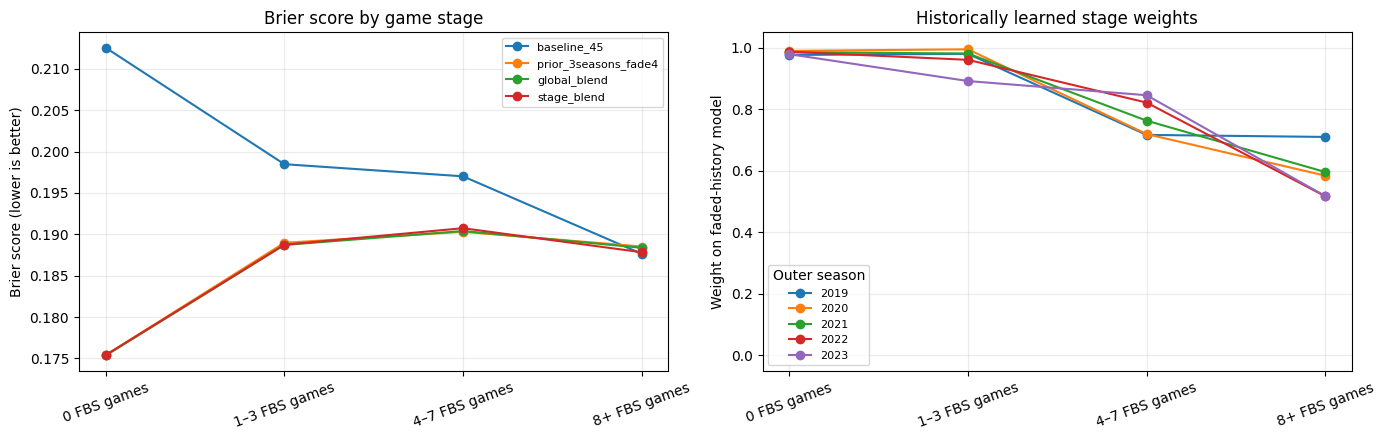

Number of validation games by stage:


,n_games
season_stage,
0 FBS games,400
1–3 FBS games,997
4–7 FBS games,1229
8+ FBS games,1020


In [ ]:
by_stage=pd.DataFrame([
    {'season_stage':str(stage),'model':name,**metrics(g.home_win,g.predicted_p_home_win)}
    for (stage,name),g in predictions.groupby(['season_stage','model'],observed=True)
])
assert by_stage.groupby('model').n_games.sum().eq(3646).all()
stage_brier=by_stage.pivot(index='season_stage',columns='model',values='brier').reindex(STAGE_ORDER)
print('Brier score by pregame stage (lower is better):')
display(stage_brier.round(5))
print('Stage blend minus no-history baseline by stage (negative = better):')
display((stage_brier['stage_blend']-stage_brier['baseline_45']).rename('delta_brier').to_frame().round(5))

fig,axes=plt.subplots(1,2,figsize=(14,4.5))
for name in ['baseline_45','prior_3seasons_fade4','global_blend','stage_blend']:
    axes[0].plot(STAGE_ORDER,stage_brier[name],marker='o',label=name)
axes[0].set(title='Brier score by game stage',ylabel='Brier score (lower is better)')
axes[0].tick_params(axis='x',rotation=20)
axes[0].grid(alpha=.25)
axes[0].legend(fontsize=8)
for year in OUTER_YEARS:
    s=weights_table.loc[weights_table.outer_validation_season.eq(year)].set_index('season_stage').reindex(STAGE_ORDER)
    axes[1].plot(STAGE_ORDER,s.smoothed_stage_alpha,marker='o',label=str(year))
axes[1].set(title='Historically learned stage weights',ylabel='Weight on faded-history model',ylim=(-.05,1.05))
axes[1].tick_params(axis='x',rotation=20)
axes[1].grid(alpha=.25)
axes[1].legend(title='Outer season',fontsize=8)
plt.tight_layout()
plt.show()

print('Number of validation games by stage:')
display(by_stage.loc[by_stage.model.eq('baseline_45'),
                 ['season_stage','n_games']].set_index('season_stage').reindex(STAGE_ORDER))

## 7. Paired diagnostics, safeguards, and interpretation



In [ ]:
paired = blended[['game_id','season','home_win','season_stage']].copy()
for name in MODEL_NAMES:
    paired[f'err_{name}']=(blended[name]-blended.home_win)**2
paired['stage_minus_fade4']=paired['err_stage_blend']-paired['err_prior_3seasons_fade4']
paired['stage_minus_baseline']=paired['err_stage_blend']-paired['err_baseline_45']
paired['global_minus_fade4']=paired['err_global_blend']-paired['err_prior_3seasons_fade4']
print('Paired Brier changes (negative is better):')
display(paired[['stage_minus_fade4','stage_minus_baseline','global_minus_fade4']].mean().to_frame('mean_change').round(6))
print('Stage blend versus fade4:')
print('  Games better:',int((paired.stage_minus_fade4<0).sum()))
print('  Games worse: ',int((paired.stage_minus_fade4>0).sum()))
print('  Same:        ',int((paired.stage_minus_fade4==0).sum()))
assert len(paired)==3646
assert np.isfinite(paired[['stage_minus_fade4','stage_minus_baseline','global_minus_fade4']].to_numpy()).all()
assert (weights_table.inner_max_season < weights_table.outer_validation_season).all()
assert not predictions.season.isin(TEST_YEARS).any()
print('Passed: matched predictions, strictly historical blend learning, untouched test seasons.')
print('IMPORTANT: Stage design is exploratory; use the reserved test for eventual confirmation only after model selection is complete.')

Paired Brier changes (negative is better):


,mean_change
stage_minus_fade4,-0.000108
stage_minus_baseline,-0.008797
global_minus_fade4,-0.000087


Stage blend versus fade4:
  Games better: 1532
  Games worse:  2114
  Same:         0
Passed: matched predictions, strictly historical blend learning, untouched test seasons.
IMPORTANT: Stage design is exploratory; use the reserved test for eventual confirmation only after model selection is complete.


## 8. Export predictions, weights, performance tables and experiment configuration



In [ ]:
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
outfiles={
    'inner_oof_predictions': OUTPUT_DIR / 'dynamic_history_inner_oof_2015_2022.csv',
    'validation_oof_predictions': OUTPUT_DIR / 'dynamic_history_oof_predictions_2019_2023.csv',
    'blending_weights': OUTPUT_DIR / 'dynamic_history_learned_weights.csv',
    'pooled_scores': OUTPUT_DIR / 'dynamic_history_pooled_scores.csv',
    'by_season_scores': OUTPUT_DIR / 'dynamic_history_scores_by_year.csv',
    'by_stage_scores': OUTPUT_DIR / 'dynamic_history_scores_by_stage.csv',
    'paired_game_errors': OUTPUT_DIR / 'dynamic_history_paired_errors.csv',
    'experiment_manifest': OUTPUT_DIR / 'dynamic_history_experiment_manifest.json',
}
inner_oof.to_csv(outfiles['inner_oof_predictions'],index=False)
predictions.to_csv(outfiles['validation_oof_predictions'],index=False)
weights_table.to_csv(outfiles['blending_weights'],index=False)
pooled.to_csv(outfiles['pooled_scores'],index=False)
per_year.to_csv(outfiles['by_season_scores'],index=False)
by_stage.to_csv(outfiles['by_stage_scores'],index=False)
paired.to_csv(outfiles['paired_game_errors'],index=False)
configuration={
    'experiment':'08 - stage-adaptive blending of prior-season and current-season models',
    'source_saved_outer_models':REFERENCE_MODELS,
    'blend_components':['baseline_45','prior_3seasons_fade4'],
    'fixed_blend_bounds':[0,1],
    'stage_categories':STAGE_ORDER,
    'inner_validation_seasons':list(range(2015,2023)),
    'outer_validation_seasons':OUTER_YEARS,
    'inner_training_rule':'train on 2004 through inner_year-1, score inner_year; learn blend weights only from inner_year < outer_year',
    'stage_alpha_shrink_pseudo_observations':SHRINK_N,
    'outer_model_predictions':'Notebook 07 saved chronological out-of-fold predictions; no outer retraining here',
    'primary_metric':'Brier score',
    'validation_game_count':3646,
    'reserved_test_seasons':sorted(TEST_YEARS),
    'software_sklearn':sklearn.__version__,
    'caveat':'The stage definitions and dynamic history idea were chosen after exploratory analysis of 2019-2023, so the outer-year comparisons are not an independent confirmation; the 2024-2025 holdout remains untested.',
}
outfiles['experiment_manifest'].write_text(json.dumps(configuration,indent=2),encoding='utf-8')
print('Saved to Google Drive:')
for name,path in outfiles.items():
    print(' -',name,':',path)
print('No 2024–2025 test predictions created.')

Saved to Google Drive:
 - inner_oof_predictions : /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/dynamic_history_inner_oof_2015_2022.csv
 - validation_oof_predictions : /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/dynamic_history_oof_predictions_2019_2023.csv
 - blending_weights : /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/dynamic_history_learned_weights.csv
 - pooled_scores : /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/dynamic_history_pooled_scores.csv
 - by_season_scores : /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/dynamic_history_scores_by_year.csv
 - by_stage_scores : /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/dynamic_history_scores_by_stage.csv
 - paired_game_errors : /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/dynamic_history_paired_errors.csv
 - experiment_manifest : /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/dynamic_history_experiment_manifest.json
No 